# 11 Disease spreading
## The agent-based SIR model

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for section 11.1 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

A disease can spread because individuals move, meet, transmit infection, and eventually recover. The model becomes interesting when these simple events interact: a single realization is unpredictable even though the rules are fixed.

**Historical reading:** W. O. Kermack and A. G. McKendrick (1927), [*A Contribution to the Mathematical Theory of Epidemics*](https://doi.org/10.1098/rspa.1927.0118), *Proc. R. Soc. A* **115**, 700–721. 

## 11.1 The agent-based SIR model

Each agent is:
- **susceptible** ($S=0$), 
- **infected** ($I=1$), 
- or **recovered and immune** ($R=2$). 

*Population:* $N$ agents (fixed)

*Initialization:* a fraction $f$ of individuals are infected.

*Arena:* square lattice (side: $L$) with periodic boundary conditions.

Several agents may occupy the same site. 

Discrete time steps.

Algorithm:

1. **Move:** *(d)* <br>Every agent moves to one of its four *von Neumann neighbors* with probability $d$; otherwise it stays.<br>

2. **Infect:** *($\beta$)* <br>Every agent infected **at the beginning of the step** independently succeeds in an infection attempt with probability $\beta$. On success it infects **all susceptible agents** sharing its *new* lattice site.<br>

3. **Recover:** *($\gamma$)* <br>Each previously infected agent recovers with probability $\gamma$.<br>

A newly infected agent begins transmitting (and becomes eligible for recovery) only at the **next** step. 

The states are taken from the beginning of the step, so results do not depend on the order in which agents are visited.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# convention 
S = 0 
I = 1 
R = 2  

we start with a **small lattice**, **small population**

In [2]:
N = 12
L = 8

positions = np.random.randint(L, size=(N, 2))

status = np.full(N, S, dtype=np.int8)

status[0] = I

print("Positions:")
print(f"{positions}")
print("States:")
print(f"{status}")


Positions:
[[5 0]
 [0 4]
 [2 2]
 [5 4]
 [6 0]
 [6 6]
 [2 3]
 [4 4]
 [5 0]
 [3 6]
 [2 2]
 [1 3]]
States:
[1 0 0 0 0 0 0 0 0 0 0 0]


Let's do a scatter plot to inspect the initial state.

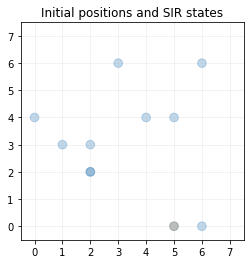

In [3]:
colors = np.array(["#337ebb", "#e58b30", "#3a9f76"])

plt.figure(figsize=(4, 4))

plt.scatter(
    positions[:, 0], 
    positions[:, 1], 
    c=colors[status], 
    s=75,
    alpha=0.3
)
plt.xlim(-0.5, L - 0.5)
plt.ylim(-0.5, L - 0.5)
plt.xticks(range(L))
plt.yticks(range(L))
plt.grid(alpha=0.2)
plt.title("Initial positions and SIR states")
plt.show()

Let's move one agent:

In [4]:
d = 0.8
move = np.random.random() < d
direction = np.random.randint(4)
dx = [1, -1, 0, 0]
dy = [0, 0, 1, -1]
print("Move?", move, "Direction index:", direction)

Move? True Direction index: 1


In [5]:
x, y = positions[0]
if move:
    x = (x + dx[direction]) % L
    y = (y + dy[direction]) % L
print("Old:", positions[0], "New:", (x, y))

new_positions = positions.copy()
new_positions[0] = (x, y)

Old: [5 0] New: (4, 0)


Let's replot:

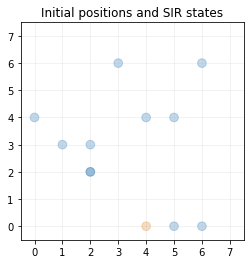

In [6]:
plt.figure(figsize=(4, 4))

plt.scatter(
    new_positions[:, 0], 
    new_positions[:, 1], 
    c=colors[status], 
    s=75,
    alpha=0.3
)
plt.xlim(-0.5, L - 0.5)
plt.ylim(-0.5, L - 0.5)
plt.xticks(range(L))
plt.yticks(range(L))
plt.grid(alpha=0.2)
plt.title("Initial positions and SIR states")
plt.show()

Now apply the same rule to each agent using an explicit loop:

In [7]:
for agent in range(N):
    if np.random.random() < d:
        direction = np.random.randint(4)
        positions[agent, 0] = (
            positions[agent, 0] + dx[direction]
        ) % L
        positions[agent, 1] = (
            positions[agent, 1] + dy[direction]
        ) % L

Let's see how the **infection** sub-step works:


Example: configuration with one infected and two susceptible co-occupants. 

For this time $\beta=1$ (for a demonstrative purpose). 

In general, we use $0<\beta<1$.

In [8]:
example_positions = np.array([[2, 3], [2, 3], [2, 3], [1, 1]])
example_status = np.array([I, S, S, R], dtype=np.int8)
beta = 1.0
print("Before:", example_status)

Before: [1 0 0 2]


In [9]:
infected_before = example_status == I
susceptible_before = example_status == S

new_infections = np.zeros(len(example_status), dtype=bool)

for agent in np.where(infected_before)[0]:
    if np.random.random() < beta:
        for other in np.where(susceptible_before)[0]:
            if np.array_equal(
                example_positions[agent], 
                example_positions[other]
            ):
                new_infections[other] = True
                
example_status[new_infections] = I
print("After: ", example_status)

After:  [1 1 1 2]


Here a single successful attempt infected **both** susceptible co-occupants. With two infected people on the same site, either could succeed; the probability of at least one success is $1-(1-\beta)^2$.

Let's see how the **recovery** sub-step works:

We use a recovery mask to have the agents eligible 
The recovery mask must be constructed from the **previously infected** agents, not from the state after transmission.

In [10]:
gamma = 0.01

recovery_trials = np.random.random(N)

recovering = (status == I) & (recovery_trials < gamma)

print(f"Recovering agents: {np.where(recovering)[0]}")

Recovering agents: []


Let's put the ingredients together:

1. movement
2. infection
3. recovery 

In [11]:
d = 0.8
beta = 0.6
gamma = 0.01

previous_infected = status == I
previous_susceptible = status == S
new_infections = np.zeros(N, dtype=bool)

for agent in range(N):
    if np.random.random() < d:
        direction = np.random.randint(4)
        positions[agent] = (
            positions[agent] + [dx[direction], dy[direction]]
        ) % L
        
for agent in np.where(previous_infected)[0]:
    if np.random.random() < beta:
        for other in np.where(previous_susceptible)[0]:
            if np.array_equal(positions[agent], positions[other]):
                new_infections[other] = True
                
recovering = previous_infected & (np.random.random(N) < gamma)
status[recovering] = R
status[new_infections] = I
print(f"S, I, R: {np.bincount(status, minlength=3)}")

S, I, R: [11  1  0]


Let's run a simulation with more particles in a larger lattice.

In [12]:
f = 0.1  # fraction of initially infected

N = 120
L = 35

n_infected_initially = max(1, round(f * N))

positions = np.random.randint(L, size=(N, 2))

status = np.full(N, S, dtype=np.int8)
status[
    np.random.choice(N, n_infected_initially, replace=False)
] = I

S_curve = [N - n_infected_initially]
I_curve = [n_infected_initially]
R_curve = [0]

In [13]:
d = 0.8
beta = 0.6
gamma = 0.01

max_steps = 250

for step in range(max_steps):
    if not np.any(status == I):
        break
    previous_infected = status == I
    previous_susceptible = status == S
    new_infections = np.zeros(N, dtype=bool)

    for agent in range(N):
        if np.random.random() < d:
            direction = np.random.randint(4)
            positions[agent] = (
                positions[agent] 
                + [dx[direction], dy[direction]]
            ) % L

    for agent in np.where(previous_infected)[0]:
        if np.random.random() < beta:
            for other in np.where(previous_susceptible)[0]:
                if np.array_equal(
                    positions[agent], positions[other]
                ):
                    new_infections[other] = True

    status[
        previous_infected 
        & (np.random.random(N) < gamma)
    ] = R
    status[new_infections] = I
    counts = np.bincount(status, minlength=3)
    S_curve.append(counts[S])
    I_curve.append(counts[I]) 
    R_curve.append(counts[R])
    
print("Simulated steps:", len(I_curve) - 1)

Simulated steps: 250


Let's check that
- the population is conserved
- if the epidemic has died out

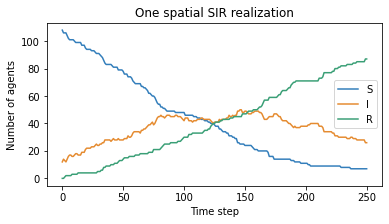

In [14]:
assert np.all(
    np.array(S_curve) + np.array(I_curve) + np.array(R_curve) 
    == N
)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(S_curve, label="S", color=colors[S])
ax.plot(I_curve, label="I", color=colors[I])
ax.plot(R_curve, label="R", color=colors[R])
ax.set(
    xlabel="Time step", 
    ylabel="Number of agents", 
    title="One spatial SIR realization"
)

ax.legend()
plt.show()

Let's use the module for a faster implementation.

In [15]:
from pathlib import Path
import sys
sys.path.insert(0, "../11_modules")

import disease_spreading as ds

In [16]:
large_run = ds.run_sir(
    n_agents=1000, 
    side=100, 
    infected_fraction=0.01,
    d=0.8, 
    beta=0.6, 
    gamma=0.01, 
    max_steps=1500
)

print(f"Ended by extinction: {large_run['ended_by_extinction']}")
print("Last counts:")
print(f"S: {large_run['S'][-1]}")
print(f"I: {large_run['I'][-1]}")
print(f"R: {large_run['R'][-1]}")


Ended by extinction: False
Last counts:
S: 45
I: 2
R: 953


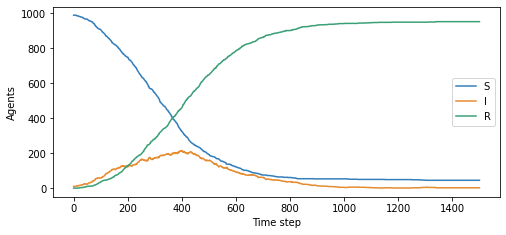

In [17]:
plt.figure(figsize=(8, 3.5))
for state, color in zip("SIR", colors):
    plt.plot(
        large_run["time"], 
        large_run[state], 
        color=color, 
        label=state
    )
plt.xlabel("Time step")
plt.ylabel("Agents")
plt.legend()
plt.show()

Let's see an animation of the SIR model

In [18]:
from pathlib import Path
import sys
sys.path.insert(0, "../11_modules")

import ds_visualize as vis

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [19]:
animation_history = vis.animate_sir(
    n_agents=500, 
    side=50, 
    beta=0.8,
    gamma=0.01, 
    max_steps=600,
    steps_per_frame=1,
    window_size=200
)

print("Rendered steps:", len(animation_history) - 1)

Rendered steps: 600


<a id="questions"></a>
## Questions

- [Q1: SIR model and agents](#q1)

- [Q2: Infection](#q2)

- [Q3: Recovery](#q3)

- [Q5: Epidemic evolution](#q4)

<a id="q1"></a>
### Q1: SIR model and agents

Refer to the generalities of agent-based SIR model and the module [disease_spreading.py](../../11_modules/disease_spreading.py)

[Go back to questions](#questions)

**a.** You want to modify the rule for the mobility of the agents by allowing them to move also diagonally, i.e., in one of the 8 first neigbour cells. How would you modify the function `step_agent` in the module? Explain.

**b.** You want to introduce a differential mobility for the infected agents: instead of moving with probability `d`, they move with probability `d_I`, different from `d`.  How would you modify the function `step_agent` in the module? Explain.

**c.** In `step_agent`, you find the following lines:
```python 
    existing_infected = status == INFECTED
    existing_recovered = status == RECOVERED
    susceptible = status == SUSCEPTIBLE
```
Explain if the following code:
```python 
    (existing_infected = status) == INFECTED
    (existing_recovered = status) == RECOVERED
    (susceptible = status) == SUSCEPTIBLE
```
is equivalent to the lines we find in `step_agent`. Motivate your answer.




<a id="q2"></a>
### Q2: Infection

Refer to the generalities of agent-based SIR model and the module [disease_spreading.py](../../11_modules/disease_spreading.py)

[Go back to questions](#questions)

**a.** Modify the code in `step_agent` to implement the *infection* step in the following way: 
- for each cell containing both infected and susceptible agents, you allow a single susceptible individual to be infected with probability $\beta$ for each single infected agent in the cell.
How do you modify the function? Explain.

**b.** Modify the code in `step_agent` to implement the *infection* step in after the recovery. 
How do you modify the function? Explain.

**c.** Modify the `step_agent` function to account for *indirect transmission*: a cell occupied by one or more infected agents at a given time step can infect susceptible agents occupying the same cell at the next time step, with probability $\beta_{\mathrm{cell}}$.

How would you modify the function to incorporate this mechanism? Explain your reasoning.


<a id="q3"></a>
### Q3: Recovery

Refer to the generalities of agent-based SIR model and the module [disease_spreading.py](../../11_modules/disease_spreading.py)

[Go back to questions](#questions)

**a.** In the examples, we have seen the effect of a recovery rate `gamma = 0.01`. Explain what would happen if `gamma = 0.5`. 

**b.** Once an agent is infected in the basic SIR model, what is the average number of time steps it takes to recover? How would you measure this with a simulation? Explain.




<a id="q4"></a>
### Q4: Epidemic evolution

Refer to the curves showing the trend of S, I, R population in time.

[Go back to questions](#questions)

**a.** In the agent-based SIR model, how does the course of the epidemic depend on the density of agents?

What would you expect to observe for a population of `1000 agents` on a square lattice with side length `L = 1000`? Explain your reasoning.

**b.** What is the effect on the epidemic curves of an increased mobility `d`, when all other parameters are kept constant?

**c.** Assume `d = 0`, `beta = 0.5`, `gamma = 0.01`, `N = 1000`, `L = 2`, and there is **exactly one** initially infected agent.

What would you expect the final number of recovered agents to be once the epidemic has died out? Explain your reasoning.
